# Fraud risk analysis
Supplied data; hypothetical cost assumptions. No valid transaction timestamp exists, so results are not temporal validation.

## 1. Environment and reproducibility
Run from the repository root with dependencies in `requirements.txt`. The experiment uses seed 42 plus documented split seeds 43-45.

In [1]:
%run scripts/run_analysis.py --data data/raw/transaction_fraud_risk_advanced_dataset.csv

{
  "selected_model": "logistic_plain_base",
  "calibration": "sigmoid",
  "policy": {
    "review": 0.12419255718131021,
    "block": 0.1329095354664825
  },
  "selection_metrics": {
    "roc_auc": 0.6603452243958572,
    "average_precision": 0.28911517346764026,
    "brier": 0.10104377040590894,
    "log_loss": 0.3650752137587634
  },
  "calibration_metrics": {
    "method": "sigmoid",
    "roc_auc": 0.6389824167601944,
    "average_precision": 0.22078956184848186,
    "brier": 0.1041836384948227,
    "log_loss": 0.3604638404493773
  },
  "test_metrics": {
    "roc_auc": 0.6514777364768267,
    "average_precision": 0.21101291795049917,
    "brier": 0.10527934587963808,
    "log_loss": 0.363215584720544,
    "precision_at_review": 0.20253164556962025,
    "recall_at_review": 0.4383561643835616,
    "f1_at_review": 0.27705627705627706,
    "confusion_at_review": [
      [
        401,
        126
      ],
      [
        41,
        32
      ]
    ]
  },
  "test_policy": {
    "review_

In [2]:
import json, pandas as pd
from IPython.display import display, Image
audit=json.load(open('reports/data_audit.json'))
results=json.load(open('reports/results.json'))
audit

{'source': 'transaction_fraud_risk_advanced_dataset.csv',
 'shape': [3000, 25],
 'fraud_counts': {'0': 2636, '1': 364},
 'missing': {'transaction_id': 0,
  'hour': 0,
  'day_of_week': 0,
  'transaction_amount': 53,
  'distance_from_usual_location_km': 75,
  'transactions_last_1h': 0,
  'transactions_last_24h': 0,
  'account_age_days': 0,
  'failed_logins_24h': 0,
  'prior_chargebacks': 0,
  'device_age_days': 0,
  'merchant_risk_score': 60,
  'ip_risk_score': 45,
  'email_age_days': 0,
  'login_to_transaction_minutes': 60,
  'card_presence': 0,
  'channel': 0,
  'country': 0,
  'device_type': 0,
  'merchant_category': 0,
  'authentication_level': 289,
  'new_device': 0,
  'billing_address_mismatch': 0,
  'customer_tier': 0,
  'fraud': 0},
 'duplicates': 0,
 'duplicate_ids': 0,
 'partitions': {'train': {'rows': 1500, 'fraud': 182},
  'selection': {'rows': 450, 'fraud': 55},
  'calibration_fit': {'rows': 225, 'fraud': 27},
  'policy_selection': {'rows': 225, 'fraud': 27},
  'test': {'row

## 2. Data audit and leakage
See the machine-readable audit above. Chargebacks, velocity, distance and upstream scores need proof of availability at authorization time. Transaction IDs and the target are excluded from fitting.

,missing
transaction_id,0
hour,0
day_of_week,0
transaction_amount,53
distance_from_usual_location_km,75
transactions_last_1h,0
transactions_last_24h,0
account_age_days,0
failed_logins_24h,0
prior_chargebacks,0


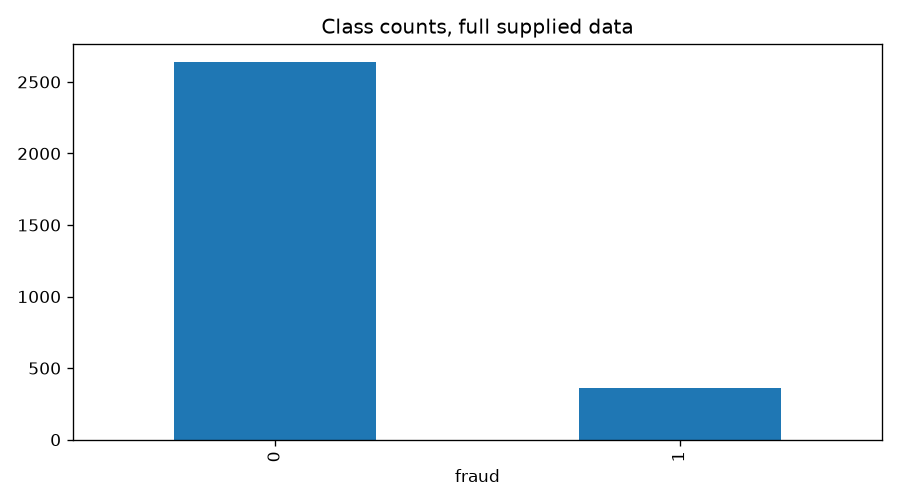

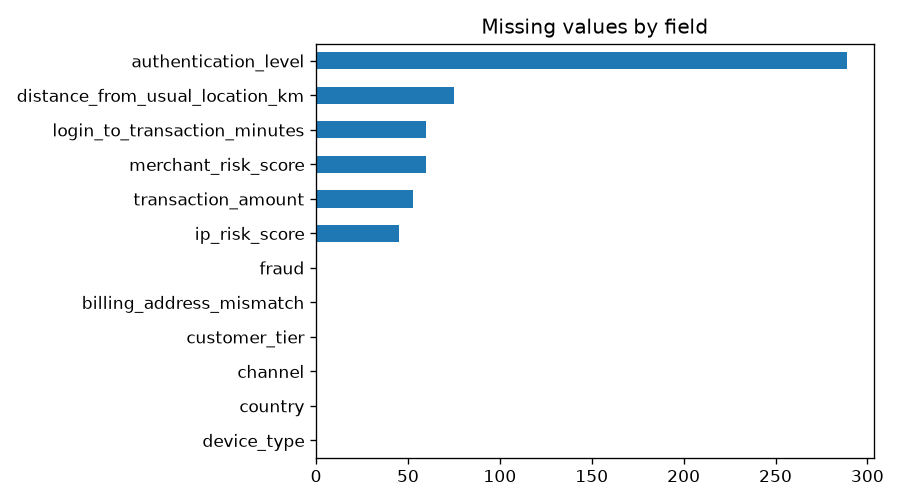

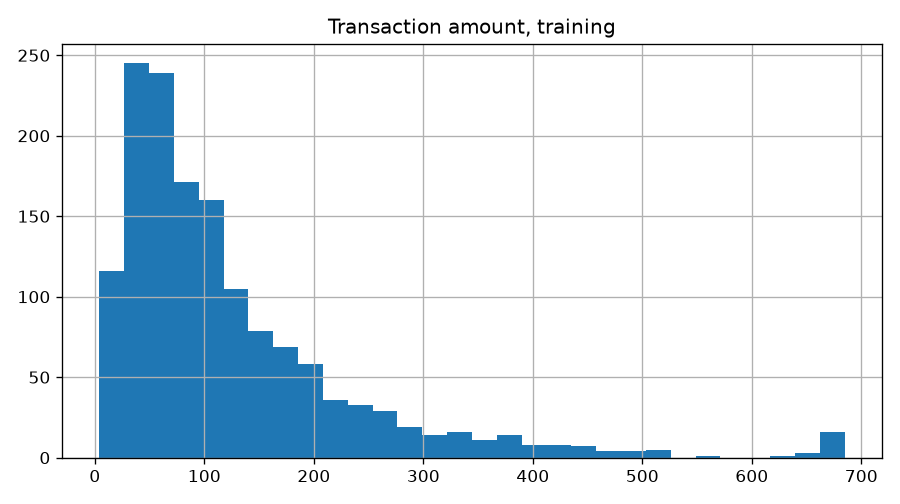

In [3]:
display(pd.DataFrame({'missing':audit['missing']}))
for i in range(1,4): display(Image(filename=f'reports/figure_{i:02d}.png'))

## 3. Training-only exploratory analysis
Associations are descriptive. Interaction charts have small cells and should not be read causally.

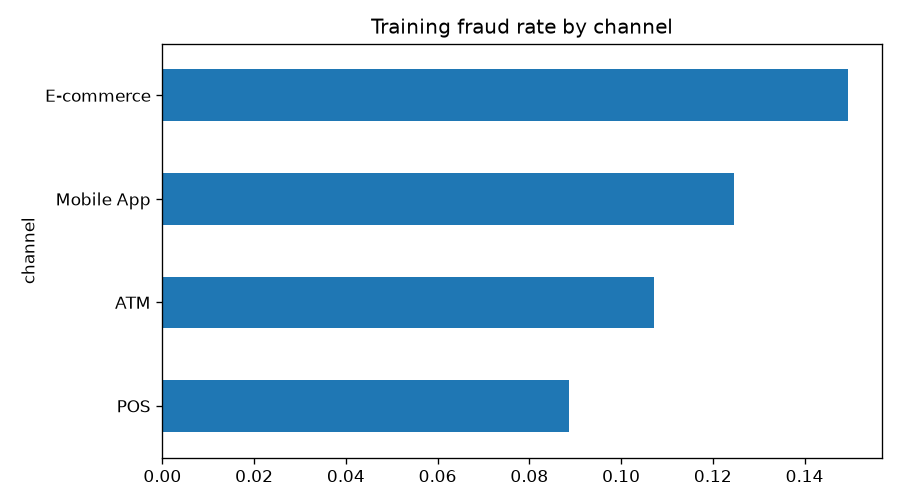

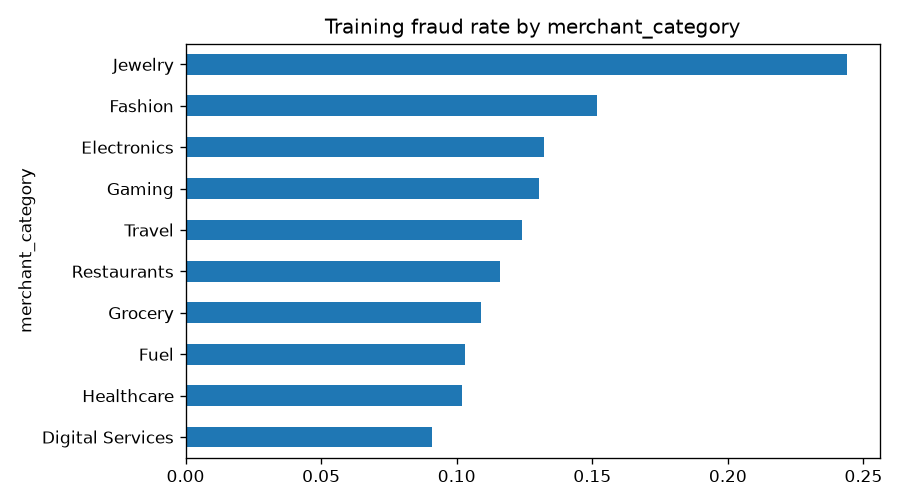

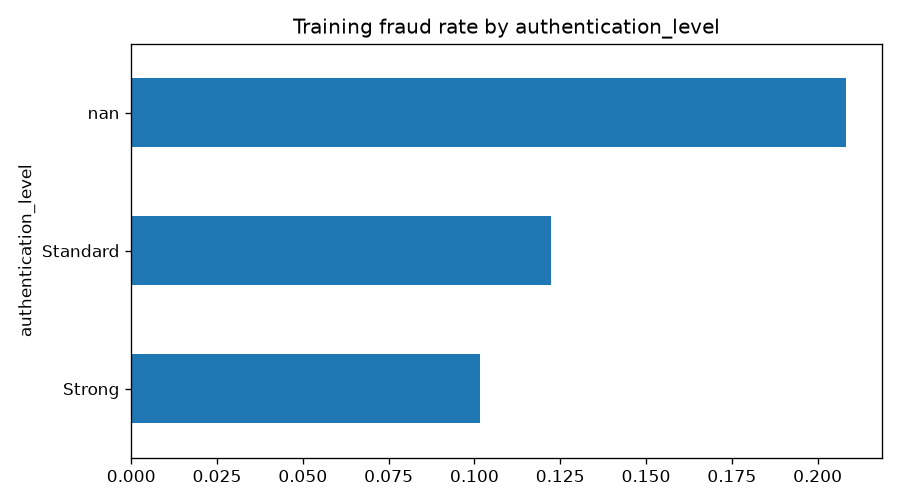

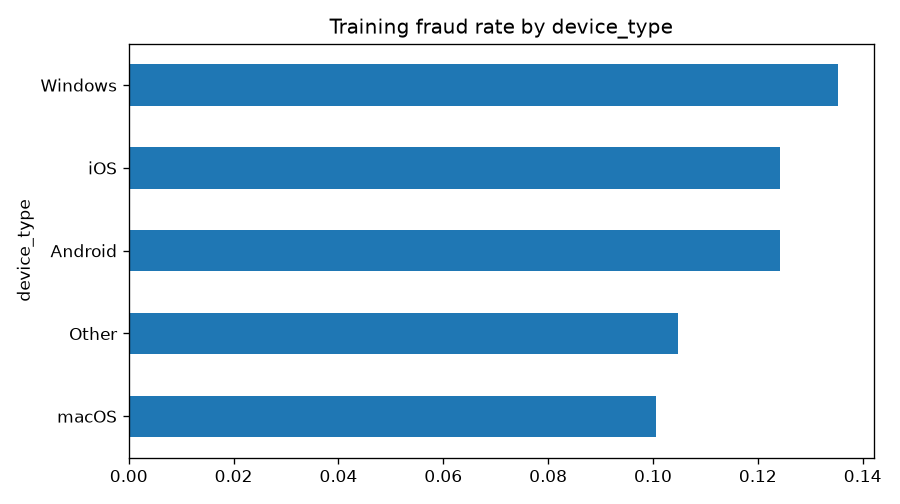

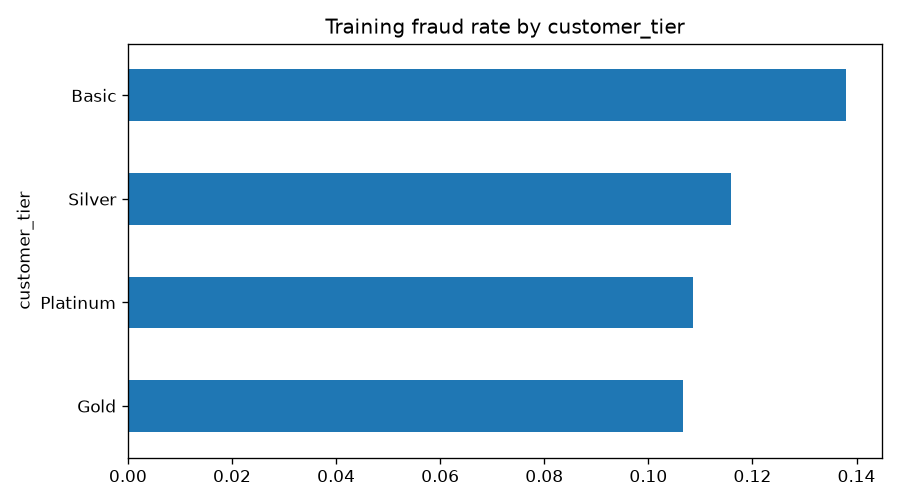

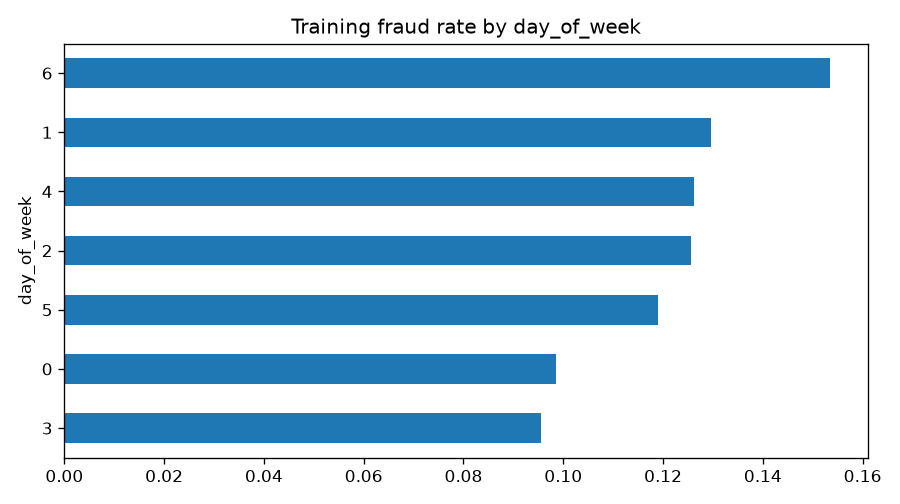

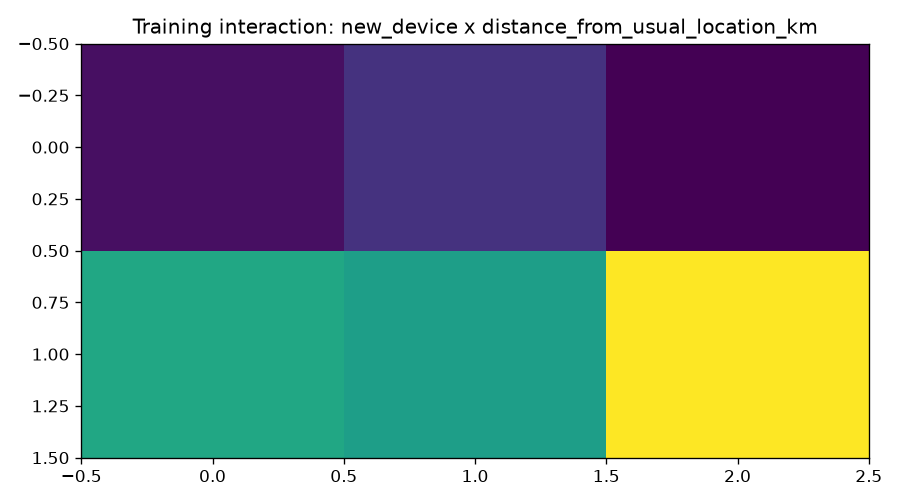

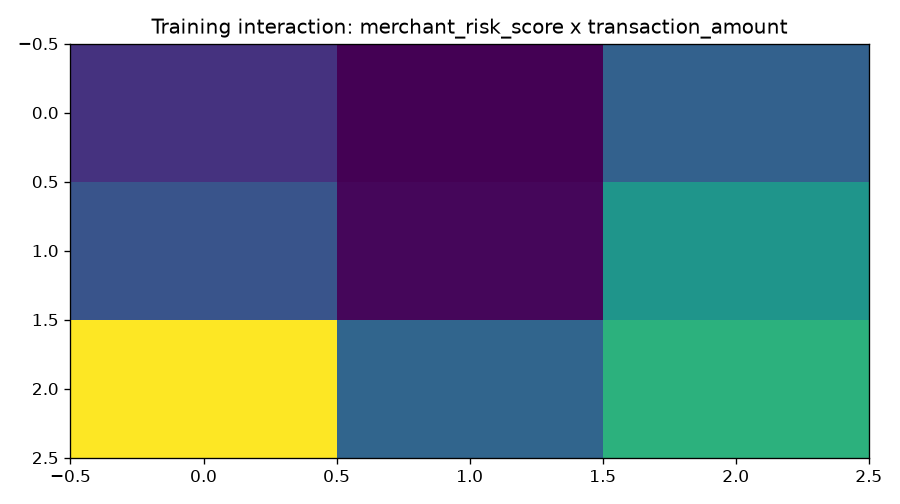

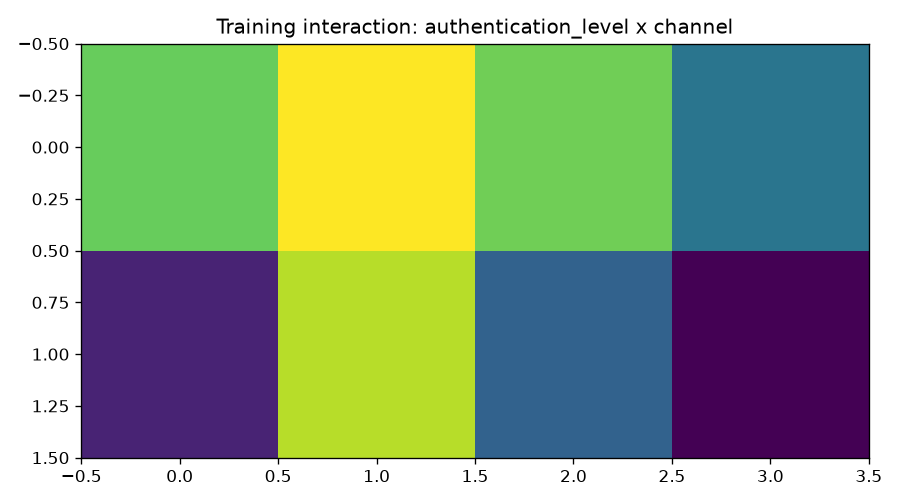

In [4]:
for i in range(4,13): display(Image(filename=f'reports/figure_{i:02d}.png'))

## 4. Feature engineering and validation
Row-local features are defined in `fraud_pipeline.core.features`. No customer history is reconstructed without customer IDs and timestamps. Stratified train, selection, calibration-fit, policy-selection and test partitions are disjoint.

In [5]:
display(pd.DataFrame(audit['partitions']).T)

,rows,fraud
train,1500,182
selection,450,55
calibration_fit,225,27
policy_selection,225,27
test,600,73


## 5. Baseline, nonlinear models and imbalance
Unweighted and class-weighted logistic, random forest and extra trees models are compared with baseline and engineered features. Selection uses average precision.

In [6]:
display(pd.read_csv('reports/model_comparison.csv'))
display(pd.read_csv('reports/feature_importance.csv').head(12))

,name,roc_auc,average_precision,brier,log_loss
0,logistic_plain_base,0.660345,0.289115,0.101044,0.365075
1,logistic_weighted_base,0.645109,0.266017,0.229258,0.668007
2,logistic_plain_engineered,0.678021,0.264203,0.101419,0.363796
3,forest_plain_engineered,0.665547,0.254628,0.102216,0.350812
4,logistic_weighted_engineered,0.670978,0.247900,0.225413,0.657990
5,extra_trees_plain_engineered,0.624028,0.239003,0.104267,0.359496
6,forest_weighted_engineered,0.669183,0.238792,0.154384,0.489762
7,forest_plain_base,0.621082,0.228846,0.104434,0.359457
8,extra_trees_weighted_base,0.594845,0.201591,0.154060,0.487483
9,extra_trees_plain_base,0.590334,0.201251,0.105827,0.367434


,feature,ap_drop_mean,ap_drop_sd
0,prior_chargebacks,0.057747,0.007382
1,new_device,0.050912,0.006316
2,merchant_category,0.049698,0.010903
3,transactions_last_1h,0.042090,0.019408
4,channel,0.027903,0.015989
5,merchant_risk_score,0.027493,0.015371
6,customer_tier,0.026298,0.002043
7,billing_address_mismatch,0.020911,0.020498
8,authentication_level,0.017837,0.008893
9,country,0.016687,0.009918


## 6. Calibration
Sigmoid and isotonic calibrators fit on calibration-fit rows and are compared on policy-selection rows. These methods change probability interpretation, while ROC-AUC chiefly measures ranking.

,method,roc_auc,average_precision,brier,log_loss
0,sigmoid,0.638982,0.220790,0.104184,0.360464
1,isotonic,0.624673,0.185057,0.105291,0.627370


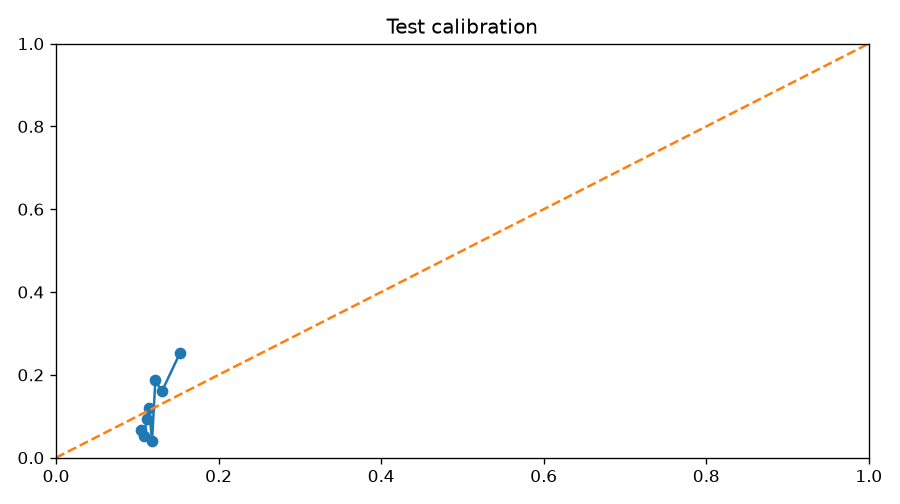

In [7]:
display(pd.read_csv('reports/calibration_comparison.csv'))
display(Image(filename='reports/figure_14.png'))

## 7. Cost optimization and operations
Costs are assumptions from `configs/cost.json`. Policy search is capacity constrained. The final test simulates outcomes after policy selection.

In [8]:
display(pd.read_csv('threshold_cost_analysis.csv').groupby('cost_scenario').apply(lambda x:x[x.capacity_ok].nsmallest(1,'total_expected_cost')).reset_index(drop=True))
display(results['test_policy'])

,model,calibration_method,review_threshold,block_threshold,total_expected_cost,cost_per_transaction,review_count,block_count,approve_count,legitimate_block_count,false_positive_count,fraud_approved_count,fraud_capture_rate,precision,recall,review_capacity_utilization,capacity_ok
0,logistic_plain_base,sigmoid,0.124193,0.132910,2852.356,12.677138,29,41,155,30,54,11,0.555556,0.228571,0.592593,0.859259,True
1,logistic_plain_base,sigmoid,0.138239,1.000000,3322.188,14.765280,27,0,198,0,18,18,0.266667,0.333333,0.333333,0.800000,True
2,logistic_plain_base,sigmoid,0.000000,0.107485,4726.984,21.008818,26,199,0,175,198,0,0.977778,0.120000,1.000000,0.770370,True
3,logistic_plain_base,sigmoid,0.124193,0.132910,2939.356,13.063804,29,41,155,30,54,11,0.555556,0.228571,0.592593,0.859259,True
4,logistic_plain_base,sigmoid,0.124193,0.132910,2981.152,13.249564,29,41,155,30,54,11,0.518519,0.228571,0.592593,0.859259,True


{'review_threshold': 0.12419255718131021,
 'block_threshold': 0.1329095354664825,
 'total_expected_cost': 9114.926,
 'cost_per_transaction': 15.191543333333332,
 'review_count': 66,
 'block_count': 92,
 'approve_count': 442,
 'legitimate_block_count': 71,
 'false_positive_count': 126,
 'fraud_approved_count': 41,
 'fraud_capture_rate': 0.40821917808219177,
 'precision': 0.20253164556962025,
 'recall': 0.4383561643835616,
 'review_capacity_utilization': 0.7333333333333333}

## 8. Explainability and robustness
Permutation importance describes model dependence, not causality. Local reason codes denote threshold routing only. Controlled perturbations retain original labels and do not emulate adaptive fraud.

In [9]:
display(pd.read_csv('reports/robustness.csv'))
display(pd.read_csv('reports/local_explanations.csv'))

,scenario,roc_auc,average_precision,brier,log_loss,review_threshold,block_threshold,total_expected_cost,cost_per_transaction,review_count,block_count,approve_count,legitimate_block_count,false_positive_count,fraud_approved_count,fraud_capture_rate,precision,recall,review_capacity_utilization,failed
0,base,0.651478,0.211013,0.105279,0.363216,0.124193,0.13291,9114.926,15.191543,66,92,442,71,126,41,0.408219,0.202532,0.438356,0.733333,0
1,amount_plus_50pct,0.652439,0.211503,0.105259,0.363127,0.124193,0.13291,8179.294,13.632157,64,95,441,73,126,40,0.421918,0.207547,0.452055,0.711111,0
2,velocity_plus_2,0.651478,0.211013,0.104896,0.361895,0.124193,0.13291,8763.978,14.606630,115,158,327,126,228,28,0.580822,0.164835,0.616438,1.277778,0
3,missing_amount_10pct,0.634998,0.199014,0.105563,0.364352,0.124193,0.13291,9293.436,15.489060,57,83,460,63,111,44,0.372603,0.207143,0.397260,0.633333,0
4,unseen_channel,0.638481,0.196358,0.105636,0.364708,0.124193,0.13291,9122.628,15.204380,81,74,445,57,126,44,0.364384,0.187097,0.397260,0.900000,0


,transaction_id,calibrated_probability,decision,top_positive_base_logit_contributions,limitation
0,TXN5002891,0.124837,REVIEW,num__new_device=0.751; cat__channel_E-commerce...,Base logistic log-odds contributions; sigmoid ...
1,TXN5002852,0.130654,REVIEW,num__transactions_last_1h=0.736; cat__merchant...,Base logistic log-odds contributions; sigmoid ...
2,TXN5001317,0.133269,BLOCK,num__prior_chargebacks=0.485; cat__merchant_ca...,Base logistic log-odds contributions; sigmoid ...
3,TXN5002371,0.128744,REVIEW,num__billing_address_mismatch=0.629; num__prio...,Base logistic log-odds contributions; sigmoid ...
4,TXN5000555,0.161191,BLOCK,num__distance_from_usual_location_km=1.875; ca...,Base logistic log-odds contributions; sigmoid ...


## 9. Final test, monitoring and limitations
Monitor input quality, unknown categories, score and decision rates, mature-label precision and calibration, and review capacity. There is no defensible claim of temporal stability, causal effects, real financial savings, fairness or deployment readiness without new data.

In [10]:
display(results['test_metrics'])
display(results['approve_all'])

{'roc_auc': 0.6514777364768267,
 'average_precision': 0.21101291795049917,
 'brier': 0.10527934587963808,
 'log_loss': 0.363215584720544,
 'precision_at_review': 0.20253164556962025,
 'recall_at_review': 0.4383561643835616,
 'f1_at_review': 0.27705627705627706,
 'confusion_at_review': [[401, 126], [41, 32]]}

{'review_threshold': 1,
 'block_threshold': 1,
 'total_expected_cost': 12103.02,
 'cost_per_transaction': 20.1717,
 'review_count': 0,
 'block_count': 0,
 'approve_count': 600,
 'legitimate_block_count': 0,
 'false_positive_count': 0,
 'fraud_approved_count': 73,
 'fraud_capture_rate': 0.0,
 'precision': 0.0,
 'recall': 0.0,
 'review_capacity_utilization': 0.0}